In [ ]:
# --------------------------------------------------------------------------
# 0. Libraries and Reproducibility
# --------------------------------------------------------------------------
import sys
import os
import warnings
import numpy as np
import matplotlib
import scipy
import sklearn
import matplotlib.pyplot as plt
from scipy.optimize import least_squares, minimize
from scipy.stats import norm, skew, spearmanr, qmc
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, RBF, ConstantKernel, WhiteKernel
warnings.filterwarnings("ignore")

# ---------------------------------------------------------------- 
# Figures settings
# ---------------------------------------------------------------- 
SURFACE, INK, INK2, MUTED, GRIDC = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e6e5e1"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": INK, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRIDC, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

SEED = 42
print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()

Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



In [2]:
# ---------------------------------------------------------------- 
# Load data
# ---------------------------------------------------------------- 

X = np.load('..\Function_3_Data\Week_13_Data/F3_Week_13_inputs.npy')
y = np.load('..\Function_3_Data\Week_13_Data/F3_Week_13_outputs.npy')
n, d = X.shape

N_INITIAL = 15
W12 = n - 1                       # row 26: the week-12 query (newest reading)
W11 = n - 2                       # row 25: the week-11 query
best = int(np.argmax(y))          # row 24: the week-10 query
x_best = X[best]
BEST = y[best]

print(f"n = {n} ({N_INITIAL} initial + {n - N_INITIAL} queried); newest x = {np.round(X[W12], 6)}, y = {y[W12]:.6f}")
print(f"best observed: row {best}, x = {np.round(x_best, 6)}, y = {BEST:.6f}")
print(f"newest ranks {int((y > y[W12]).sum()) + 1} of {n} by y; distance from the best point {np.linalg.norm(X[W12] - x_best):.4f}; "
      f"its y is {BEST - y[W12]:.6f} below the best")
assert best == 24 and W12 == 26

n = 27 (15 initial + 12 queried); newest x = [0.441119 0.582591 0.423151], y = -0.003066
best observed: row 24, x = [0.44653  0.572743 0.423725], y = -0.002265
newest ranks 2 of 27 by y; distance from the best point 0.0113; its y is 0.000801 below the best


Target Transformations (skew; gap between best and second-best value in std units)
  log   skew +0.50   gap 0.24
  sqrt  skew -0.85   gap 0.06
  raw   skew -2.66   gap 0.01


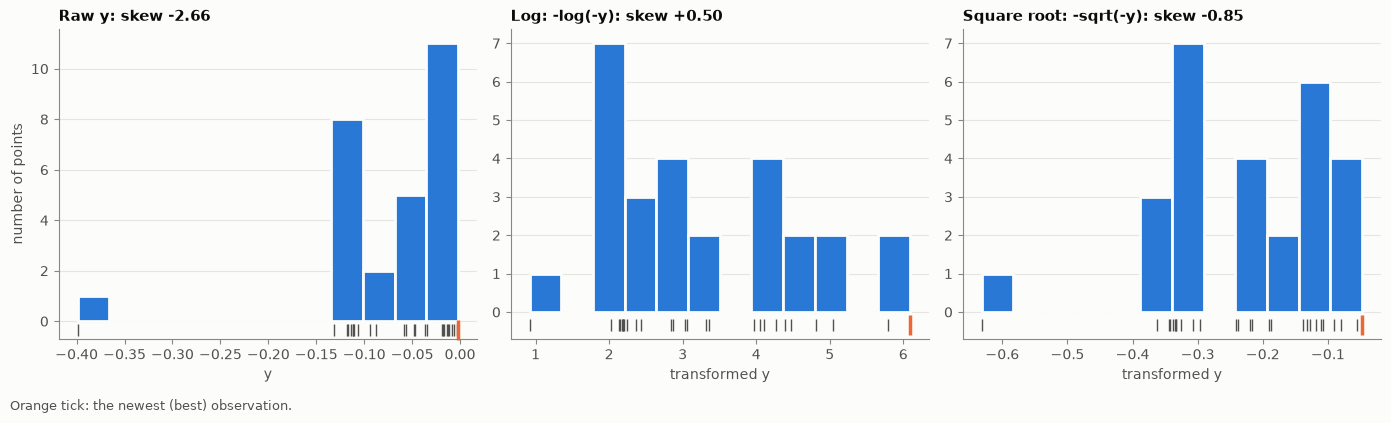

In [3]:
# ---------------------------------------------------------------- 
# Target transforms
# ---------------------------------------------------------------- 

TRANSFORMS = {
    "log": (lambda v: -np.log(-v), lambda m: -np.exp(-m)),
    "sqrt": (lambda v: -np.sqrt(-v), lambda m: -np.maximum(-m, 0) ** 2),
    "raw": (lambda v: v.copy(), lambda m: m),
}
print("=" * 100)
print("Target Transformations (skew; gap between best and second-best value in std units)")
print("=" * 100)
for name, (f, _) in TRANSFORMS.items():
    t = f(y)
    s = np.sort(t)
    print(f"  {name:5s} skew {skew(t):+.2f}   gap {(s[-1] - s[-2]) / t.std():.2f}")

# Fig 1: transforms
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (title, tname) in zip(axes, [("Raw y", "raw"), ("Log: -log(-y)", "log"), ("Square root: -sqrt(-y)", "sqrt")]):
    t = TRANSFORMS[tname][0](y)
    ax.hist(t, bins=12, color=BLUE, edgecolor=SURFACE, linewidth=2)
    ax.plot(t, np.full(n, -0.35), "|", color=INK2, markersize=9, clip_on=False)
    ax.plot(t[best], -0.35, "|", color=ORANGE, markersize=14, markeredgewidth=2.5, clip_on=False)
    ax.set_title(f"{title}: skew {skew(t):+.2f}"); ax.set_ylim(bottom=-0.7); ax.grid(axis="x", visible=False)
    ax.set_xlabel("transformed y" if tname != "raw" else "y")
axes[0].set_ylabel("number of points")
fig.text(0.01, 0.01, "Orange tick: the newest (best) observation.", color=INK2, fontsize=9)
fig.tight_layout(rect=(0, 0.04, 1, 1))

MODELS (LOO with hyperparameters fixed at the full fit)
  log-iso   ls=[0.057]  LOO RMSE/std=0.698  Spearman=0.596  raw-y RMSE on top 9=0.0041  LOO pred at best row=-0.0058  noise (normalised var)=0.094
  log-ARD   ls=[1.00e+02 6.32e-01 9.20e-02]  LOO RMSE/std=0.544  Spearman=0.819  raw-y RMSE on top 9=0.0041  LOO pred at best row=-0.0094  noise (normalised var)=0.158
  sqrt-iso  ls=[0.136]  LOO RMSE/std=0.803  Spearman=0.692  raw-y RMSE on top 9=0.0052  LOO pred at best row=-0.0061  noise (normalised var)=0.013
  sqrt-ARD  ls=[100.      1.438   0.115]  LOO RMSE/std=0.730  Spearman=0.811  raw-y RMSE on top 9=0.0034  LOO pred at best row=-0.0089  noise (normalised var)=0.026
  raw-iso   ls=[0.255]  LOO RMSE/std=0.901  Spearman=0.782  raw-y RMSE on top 9=0.0042  LOO pred at best row=-0.0056  noise (normalised var)=0.000
  raw-ARD   ls=[100.      2.      0.161]  LOO RMSE/std=1.060  Spearman=0.678  raw-y RMSE on top 9=0.0054  LOO pred at best row=-0.0087  noise (normalised var)=0.002


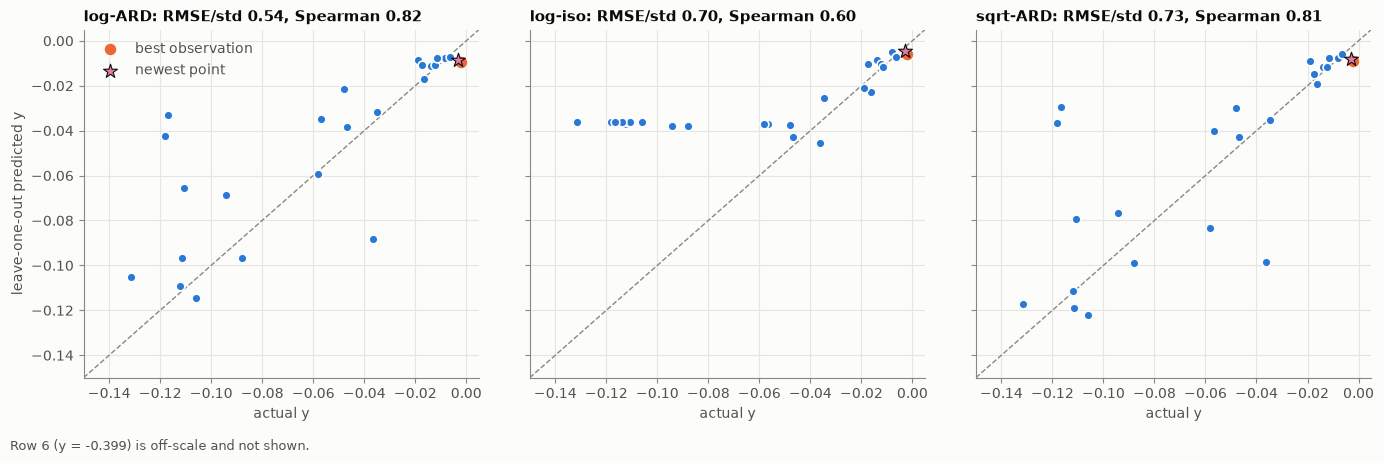

In [ ]:
# ---------------------------------------------------------------- 
# GP models + LOO
# ---------------------------------------------------------------- 

def fit(Xf, t, ard):
    k = (ConstantKernel(1.0, (1e-2, 1e2)) * Matern(length_scale=np.ones(d) if ard else 1.0,
                                      length_scale_bounds=(1e-2, 1e2), nu=2.5)
         + WhiteKernel(1e-2, (1e-8, 3e-1)))
    return GaussianProcessRegressor(kernel=k, normalize_y=True, n_restarts_optimizer=20,
                                    random_state=SEED).fit(Xf, t)

top = np.argsort(-y)[:9]
models, loos = {}, {}
print('='*100)
print("MODELS (LOO with hyperparameters fixed at the full fit)")
print('='*100)
for tname, (f, back) in TRANSFORMS.items():
    t = f(y)
    for ard in (False, True):
        key = f"{tname}-{'ARD' if ard else 'iso'}"
        gp = fit(X, t, ard)
        mu = np.empty(n)
        for i in range(n):
            keep = np.arange(n) != i
            g = GaussianProcessRegressor(kernel=gp.kernel_, optimizer=None, normalize_y=True).fit(X[keep], t[keep])
            mu[i] = g.predict(X[i:i + 1])[0]
        models[key], loos[key] = gp, mu
        yb = back(mu)
        ls = np.atleast_1d(gp.kernel_.k1.k2.length_scale)
        print(f"  {key:9s} ls={np.round(ls, 3)}  LOO RMSE/std={np.sqrt(np.mean((t - mu) ** 2)) / t.std():.3f}  "
              f"Spearman={spearmanr(t, mu)[0]:.3f}  raw-y RMSE on top 9={np.sqrt(np.mean((y[top] - yb[top]) ** 2)):.4f}  "
              f"LOO pred at best row={yb[best]:.4f}  noise (normalised var)={gp.kernel_.k2.noise_level:.3f}")

# Fig 2: LOO in raw y for three global models
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), sharey=True)
for ax, key in zip(axes, ["log-ARD", "log-iso", "sqrt-ARD"]):
    yb = TRANSFORMS[key.split('-')[0]][1](loos[key])
    t = TRANSFORMS[key.split('-')[0]][0](y)
    keep = np.arange(n) != 6
    lim = [-0.15, 0.005]
    ax.plot(lim, lim, color=MUTED, lw=1, ls="--")
    ax.scatter(y[keep], yb[keep], s=40, color=BLUE, edgecolor=SURFACE, linewidth=1.2, zorder=3)
    ax.scatter(y[best], yb[best], s=90, color=ORANGE, edgecolor=SURFACE, linewidth=1.2, zorder=4, label="best observation")
    ax.scatter(y[W12], yb[W12], s=110, marker="*", color=MAGENTA, edgecolor=INK, linewidth=0.8, zorder=4, label="newest point")
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_title(f"{key}: RMSE/std {np.sqrt(np.mean((t - loos[key]) ** 2)) / t.std():.2f}, "
                 f"Spearman {spearmanr(t, loos[key]) [0]:.2f}")
    ax.set_xlabel("actual y")
axes[0].set_ylabel("leave-one-out predicted y")
axes[0].legend(frameon=False, loc="upper left", labelcolor=INK2)
fig.text(0.01, 0.01, "Row 6 (y = -0.399) is off-scale and not shown.", color=INK2, fontsize=9)
fig.tight_layout(rect=(0, 0.04, 1, 1))

In [5]:
# ---------------------------------------------------------------- 
# Week-12 predictions at the newest point
# ---------------------------------------------------------------- 

PRED_KEYS = ["log-ARD", "log-iso", "sqrt-ARD", "sqrt-iso", "raw-iso", "raw-ARD"]
prev_pred = {}
print(f"\nWEEK-12 PREDICTIONS at {np.round(X[W12], 6)} (global models refitted on the first {W12} rows); observed {y[W12]:.6f}")
for key in PRED_KEYS:
    tname, kind = key.split("-")
    f, back = TRANSFORMS[tname]
    g = fit(X[:W12], f(y[:W12]), kind == "ARD")
    m, s = g.predict(X[W12:W12 + 1], return_std=True)
    z = (f(y[W12:W12 + 1])[0] - m[0]) / s[0]
    prev_pred[key] = back(m)[0]
    print(f"  {key:9s} predicted {back(m)[0]:+.5f}   error {y[W12] - back(m)[0]:+.5f}   z (transformed, incl. noise) {z:+.2f}")

# ---------------------------------------------------------------- 
# Local bowl model
# -y = e + b1 (x1-c1)^2 + b2 (x2-c2)^2 + b3 (x3-c3)^2 on the cluster of best points
#-----------------------------------------------------------------

CL_WK12 = [3, 16, 17, 18, 20, 21, 22, 23, 24, 25]      # the cluster behind the week-12 bowl (adds the week-11 query)
CL_WK11 = [3, 16, 17, 18, 20, 21, 22, 23, 24]          # the week-11 bowl
CL = CL_WK12 + [W12]                                   # + the week-12 query: 11 points
LB, UB = [0, 0, 0, 0, 0, 0, 0], [1, 1e4, 1e4, 1e4, 1, 1, 1]
def bowl_res(p, Z, v):
    e, b1, b2, b3, c1, c2, c3 = p
    return e + b1 * (Z[:, 0] - c1) ** 2 + b2 * (Z[:, 1] - c2) ** 2 + b3 * (Z[:, 2] - c3) ** 2 - v

def fit_bowl(rows):
    p = least_squares(bowl_res, [0.002, 1, 1, 1, 0.45, 0.57, 0.42], args=(X[rows], -y[rows]), bounds=(LB, UB)).x
    jk = np.array([least_squares(bowl_res, p, args=(X[[j for j in rows if j != i]], -y[[j for j in rows if j != i]]),
                                 bounds=(LB, UB)).x[4:] for i in rows])
    return p, jk

def make_bowl(p):
    def f(Z):
        e, b1, b2, b3, c1, c2, c3 = p
        return -(e + b1 * (Z[:, 0] - c1) ** 2 + b2 * (Z[:, 1] - c2) ** 2 + b3 * (Z[:, 2] - c3) ** 2)
    return f

p_w12, _ = fit_bowl(CL_WK12)
bowl_w12 = make_bowl(p_w12)
p_bowl, jack = fit_bowl(CL)
bowl = make_bowl(p_bowl)
centre = p_bowl[4:]
print(f"\nWEEK-12 BOWL (10 points): centre {np.round(p_w12[4:], 4)}, curvatures {np.round(p_w12[1:4], 2)}; "
      f"predicted {bowl_w12(X[W12:W12 + 1])[0]:+.5f} at the newest point (observed {y[W12]:+.5f})")
print(f"BOWL MODEL on rows {CL}: floor e = {p_bowl[0]:.6f}, curvatures b = {np.round(p_bowl[1:4], 2)}, centre = {np.round(centre, 6)}")
print(f"  residuals (bowl - y): {np.round(bowl(X[CL]) - y[CL], 4)}   rms {np.sqrt(np.mean((bowl(X[CL]) - y[CL]) ** 2)):.4f}")
print(f"  leave-one-out centres: min {np.round(jack.min(0), 3)}, max {np.round(jack.max(0), 3)}")
print(f"  bowl at best point {bowl(x_best[None])[0]:+.5f} (observed {BEST:+.5f}); bowl at centre {bowl(centre[None])[0]:+.5f}")




WEEK-12 PREDICTIONS at [0.441119 0.582591 0.423151] (global models refitted on the first 26 rows); observed -0.003066
  log-ARD   predicted -0.00880   error +0.00574   z (transformed, incl. noise) +2.11
  log-iso   predicted -0.00661   error +0.00354   z (transformed, incl. noise) +1.34
  sqrt-ARD  predicted -0.00809   error +0.00502   z (transformed, incl. noise) +1.59
  sqrt-iso  predicted -0.00630   error +0.00323   z (transformed, incl. noise) +1.00
  raw-iso   predicted -0.00396   error +0.00089   z (transformed, incl. noise) +0.29
  raw-ARD   predicted -0.00735   error +0.00429   z (transformed, incl. noise) +1.19

WEEK-12 BOWL (10 points): centre [0.4569 0.5915 0.4136], curvatures [3.99 1.7  4.38]; predicted -0.00683 at the newest point (observed -0.00307)
BOWL MODEL on rows [3, 16, 17, 18, 20, 21, 22, 23, 24, 25, 26]: floor e = 0.004708, curvatures b = [3.57 1.7  4.51], centre = [0.454882 0.594441 0.414137]
  residuals (bowl - y): [-0.0001 -0.0018  0.0018 -0.0005  0.0021  0.00

In [6]:
# ---------------------------------------------------------------- 
# Local GP ensemble
# ---------------------------------------------------------------- 

R_LOC = 0.12
def local_kernel(kind):
    ls = np.ones(d)
    base = RBF(length_scale=ls, length_scale_bounds=(0.01, 10)) if kind == "rbf" else \
        Matern(length_scale=ls, length_scale_bounds=(0.01, 10), nu=kind)
    return ConstantKernel(1.0, (1e-3, 1e3)) * base + WhiteKernel(1e-4, (1e-9, 1e-1))

LOCAL_KINDS = {"local M5/2 ARD": 2.5, "local M3/2 ARD": 1.5, "local RBF ARD": "rbf"}
def fit_local(rows_all, kind):
    b = rows_all[np.argmax(y[rows_all])]
    rows = rows_all[np.linalg.norm(X[rows_all] - X[b], axis=1) < R_LOC]
    g = GaussianProcessRegressor(kernel=local_kernel(LOCAL_KINDS[kind]), normalize_y=True, n_restarts_optimizer=15,
                                 random_state=SEED).fit(X[rows], y[rows])
    return g, rows

locs = {k: fit_local(np.arange(n), k) for k in LOCAL_KINDS}
loc_rows = locs["local M5/2 ARD"][1]
print(f"\nLOCAL GP ENSEMBLE: trained on the {len(loc_rows)} readings within {R_LOC} of the best point (rows {sorted(loc_rows.tolist())})")
for k, (g, rows) in locs.items():
    print(f"  {k}: {g.kernel_}")
# leave-one-out inside the local set (hyperparameters fixed), error on the best six
top6 = np.argsort(-y)[:6]
print("  leave-one-out RMSE on the six best readings: ", end="")
loc_err = {}
for k, (g, rows) in locs.items():
    pr = np.empty(len(rows))
    for a, i in enumerate(rows):
        keep = [j for j in range(len(rows)) if j != a]
        gg = GaussianProcessRegressor(kernel=g.kernel_, optimizer=None, normalize_y=True).fit(X[rows][keep], y[rows][keep])
        pr[a] = gg.predict(X[i:i + 1])[0]
    mask = np.isin(rows, top6)
    loc_err[k] = np.sqrt(np.mean((pr[mask] - y[rows][mask]) ** 2))
    print(f"{k}: {loc_err[k]:.5f}  ", end="")
print(f"\n  (global models, top-9: " + ", ".join(f"{k} {np.sqrt(np.mean((TRANSFORMS[k.split('-')[0]][1](loos[k])[top] - y[top]) ** 2)):.4f}" for k in ["log-ARD", "sqrt-ARD", "raw-iso"]) + ")")

# rolling-origin forward test: local ensemble trained on rows before i, predicting row i
print("\nFORWARD TEST of the local ensemble (trained only on rows before the one predicted)")
fwd = {}
for i in range(21, n):
    out = []
    for k in LOCAL_KINDS:
        g, rows = fit_local(np.arange(i), k)
        m, s = g.predict(X[i:i + 1], return_std=True)
        out.append((m[0], s[0]))
    fwd[i] = out
    print(f"  row {i}: actual {y[i]:+.5f}  " + "  ".join(f"{k.split()[1]}: {m:+.5f} (err {y[i] - m:+.5f}, {(y[i] - m) / s:+.1f} sd)"
                                                      for k, (m, s) in zip(LOCAL_KINDS, out)))
wk12_local = {k: fwd[W12][j] for j, k in enumerate(LOCAL_KINDS)}


LOCAL GP ENSEMBLE: trained on the 11 readings within 0.12 of the best point (rows [3, 16, 17, 18, 20, 21, 22, 23, 24, 25, 26])
  local M5/2 ARD: 1.18**2 * Matern(length_scale=[0.0973, 0.0697, 0.0314], nu=2.5) + WhiteKernel(noise_level=0.0336)
  local M3/2 ARD: 1.21**2 * Matern(length_scale=[0.12, 0.0861, 0.0349], nu=1.5) + WhiteKernel(noise_level=0.0298)
  local RBF ARD: 1.11**2 * RBF(length_scale=[0.0693, 0.0513, 0.0247]) + WhiteKernel(noise_level=0.0344)
  leave-one-out RMSE on the six best readings: local M5/2 ARD: 0.00185  local M3/2 ARD: 0.00186  local RBF ARD: 0.00181  
  (global models, top-9: log-ARD 0.0041, sqrt-ARD 0.0034, raw-iso 0.0042)

FORWARD TEST of the local ensemble (trained only on rows before the one predicted)
  row 21: actual -0.00817  M5/2: -0.01429 (err +0.00612, +1.1 sd)  M3/2: -0.01475 (err +0.00658, +1.1 sd)  RBF: -0.01372 (err +0.00554, +1.2 sd)
  row 22: actual -0.01744  M5/2: -0.00798 (err -0.00946, -2.7 sd)  M3/2: -0.00961 (err -0.00782, -1.5 sd)  RBF: -

In [ ]:
# ---------------------------------------------------------------- 
# Candidates
# ----------------------------------------------------------------

S = qmc.Sobol(d, seed=1).random(2 ** 14)

def gp_pred(key, Z):
    return TRANSFORMS[key.split("-")[0]][1](models[key].predict(np.atleast_2d(Z)))

def loc_stats(k, Z):
    m, s = locs[k][0].predict(np.atleast_2d(Z), return_std=True)
    return m, s

def ei_local(Z):
    out = []
    for k in LOCAL_KINDS:
        m, s = loc_stats(k, Z)
        s = np.maximum(s, 1e-12)
        z = (m - BEST) / s
        out.append((m - BEST) * norm.cdf(z) + s * norm.pdf(z))
    return np.mean(out, axis=0)

def argmax_box(fn, r):
    lo, hi = np.clip(x_best - r, 0, 1), np.clip(x_best + r, 0, 1)
    Z = lo + S * (hi - lo)
    x0 = Z[fn(Z).argmax()]
    res = minimize(lambda q: -fn(q[None])[0], x0, bounds=list(zip(lo, hi)), method="L-BFGS-B")
    return res.x

G_KEYS = ["log-ARD", "log-iso", "sqrt-ARD", "raw-iso"]
ALL = G_KEYS + list(LOCAL_KINDS)
base = {k: gp_pred(k, x_best[None])[0] for k in G_KEYS}
base.update({k: loc_stats(k, x_best[None])[0][0] for k in LOCAL_KINDS})
def model_pred(k, Z):
    return gp_pred(k, Z) if k in G_KEYS else loc_stats(k, Z)[0]
ens_all = lambda Z: np.mean([model_pred(k, Z) - base[k] for k in ALL], axis=0)

x_ens_glob = argmax_box(lambda Z: np.mean([gp_pred(k, Z) - base[k] for k in G_KEYS], axis=0), 0.06)
x_loc_ei = argmax_box(ei_local, 0.03)
x_loc_m52 = argmax_box(lambda Z: loc_stats("local M5/2 ARD", Z)[0], 0.03)
x_ens_all = argmax_box(ens_all, 0.03)
x_ei_ard = argmax_box(lambda Z: np.zeros(len(Z)) + 0, 0.0) if False else None
cands = {
    "A: best observed point (reference)": x_best.copy(),
    "B: week-12 ensemble maximum (global GPs)": x_ens_glob,
    "C: local-ensemble EI maximum (+/-0.03 box)": x_loc_ei,
    "D: midpoint of the best point and C": 0.5 * (x_best + x_loc_ei),
    "E: mean-gain maximum of all 7 GPs (+/-0.03 box)": x_ens_all,
    "F: refitted bowl centre": centre,
}
print("\nCANDIDATES: predicted y by each model; gain = prediction minus the same model's prediction at the best point")
print("  at the best point: " + "  ".join(f"{k}={v:+.4f}" for k, v in base.items()) + f"  bowl={bowl(x_best[None])[0]:+.4f}  (observed {BEST:+.5f})")
gains, preds = {}, {}
for name, xc in cands.items():
    p = {k: float(model_pred(k, xc[None])[0]) for k in ALL}
    p["bowl"] = float(bowl(xc[None])[0])
    preds[name] = p
    g_ = {k: p[k] - (base[k] if k != "bowl" else bowl(x_best[None])[0]) for k in p}
    gains[name] = g_
    gv = [g_[k] for k in ALL]
    print(f"  {name:52s} x = ({xc[0]:.6f}, {xc[1]:.6f}, {xc[2]:.6f})  dist {np.linalg.norm(xc - x_best):.3f}")
    print("      predicted: " + "  ".join(f"{k.replace('local ', 'L-')}={v:+.4f}" for k, v in p.items()))
    print("      gain     : " + "  ".join(f"{k.replace('local ', 'L-')}={v:+.4f}" for k, v in g_.items())
          + f"  | mean (7 GPs) {np.mean(gv):+.4f}, models predicting a gain: {sum(v > 1e-9 for v in gv)} of 7")
    if name[0] != "A":
        ms = [(loc_stats(k, xc[None])[0][0], loc_stats(k, xc[None])[1][0]) for k in LOCAL_KINDS]
        print("      local GPs vs the best observed value: " + "  ".join(f"{k.split()[1]} {m - BEST:+.5f} (sd {s:.4f})" for k, (m, s) in zip(LOCAL_KINDS, ms)))


CANDIDATES: predicted y by each model; gain = prediction minus the same model's prediction at the best point
  at the best point: log-ARD=-0.0078  log-iso=-0.0043  sqrt-ARD=-0.0076  raw-iso=-0.0043  local M5/2 ARD=-0.0042  local M3/2 ARD=-0.0039  local RBF ARD=-0.0042  bowl=-0.0062  (observed -0.00226)
  A: best observed point (reference)                   x = (0.446530, 0.572743, 0.423725)  dist 0.000
      predicted: log-ARD=-0.0078  log-iso=-0.0043  sqrt-ARD=-0.0076  raw-iso=-0.0043  L-M5/2 ARD=-0.0042  L-M3/2 ARD=-0.0039  L-RBF ARD=-0.0042  bowl=-0.0062
      gain     : log-ARD=+0.0000  log-iso=+0.0000  sqrt-ARD=+0.0000  raw-iso=+0.0000  L-M5/2 ARD=+0.0000  L-M3/2 ARD=+0.0000  L-RBF ARD=+0.0000  bowl=+0.0000  | mean (7 GPs) +0.0000, models predicting a gain: 0 of 7
  B: week-12 ensemble maximum (global GPs)             x = (0.430556, 0.591300, 0.424842)  dist 0.025
      predicted: log-ARD=-0.0075  log-iso=-0.0043  sqrt-ARD=-0.0068  raw-iso=-0.0023  L-M5/2 ARD=-0.0028  L-M3/2 ARD=

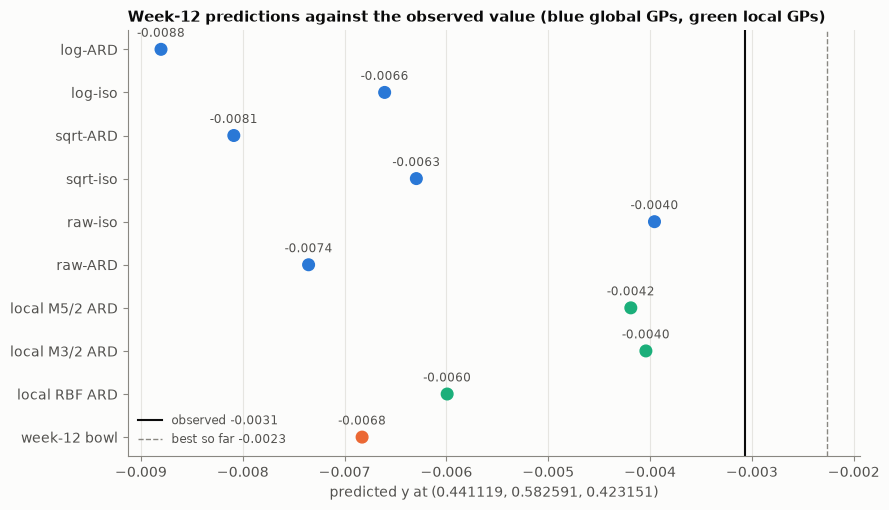

In [ ]:
# Fig 3: week-12 predictions vs outcome (global, local and bowl)
fig, ax = plt.subplots(figsize=(9, 5.2))
names = PRED_KEYS + list(LOCAL_KINDS) + ["week-12 bowl"]
vals = [prev_pred[k] for k in PRED_KEYS] + [wk12_local[k][0] for k in LOCAL_KINDS] + [bowl_w12(X[W12:W12 + 1])[0]]
cols = [BLUE] * len(PRED_KEYS) + [AQUA] * len(LOCAL_KINDS) + [ORANGE]
ypos = np.arange(len(names))[::-1]
ax.scatter(vals, ypos, s=70, color=cols, zorder=3)
ax.axvline(y[W12], color=INK, lw=1.5, label=f"observed {y[W12]:.4f}")
ax.axvline(BEST, color=MUTED, lw=1, ls="--", label=f"best so far {BEST:.4f}")
for v_, p_ in zip(vals, ypos):
    ax.annotate(f"{v_:.4f}", (v_, p_), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=8.5, color=INK2)
ax.set_yticks(ypos); ax.set_yticklabels(names)
ax.set_xlabel(f"predicted y at ({X[W12, 0]:.6f}, {X[W12, 1]:.6f}, {X[W12, 2]:.6f})")
ax.set_title("Week-12 predictions against the observed value (blue global GPs, green local GPs)")
ax.legend(frameon=False, loc="lower left", fontsize=8.5, labelcolor=INK2)
ax.grid(axis="y", visible=False)
fig.tight_layout()

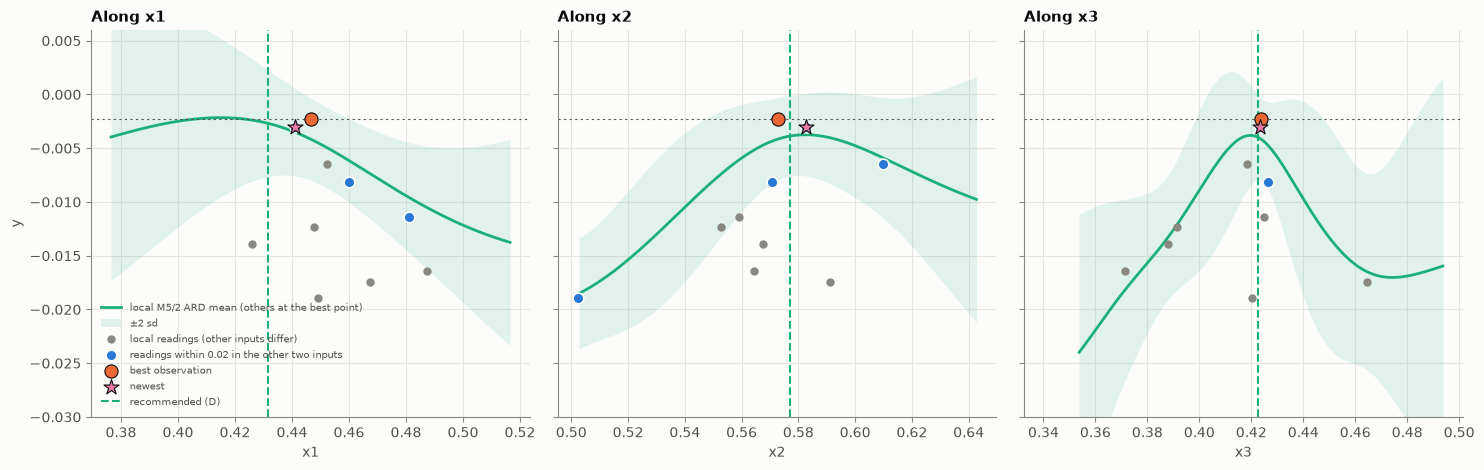

In [9]:
# Fig 4: local GP through the best point along each input, with the nearby readings and candidates
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
gM = locs["local M5/2 ARD"][0]
cD = cands["D: midpoint of the best point and C"]
for j, ax in enumerate(axes):
    xs = np.linspace(x_best[j] - 0.07, x_best[j] + 0.07, 200)
    Z = np.tile(x_best, (len(xs), 1)); Z[:, j] = xs
    m, s = gM.predict(Z, return_std=True)
    ax.plot(xs, m, color=AQUA, lw=2, label="local M5/2 ARD mean (others at the best point)")
    ax.fill_between(xs, m - 2 * s, m + 2 * s, color=AQUA, alpha=0.12, lw=0, label="±2 sd")
    other = [k for k in range(3) if k != j]
    near = [i for i in loc_rows if np.all(np.abs(X[i, other] - x_best[other]) < 0.02) or i == best]
    ax.scatter(X[loc_rows, j], y[loc_rows], s=25, color=MUTED, zorder=3, label="local readings (other inputs differ)")
    ax.scatter(X[near, j], y[near], s=60, color=BLUE, edgecolor=SURFACE, linewidth=1.2, zorder=4, label="readings within 0.02 in the other two inputs")
    ax.scatter(x_best[j], BEST, s=90, color=ORANGE, edgecolor=INK, linewidth=0.8, zorder=5, label="best observation")
    ax.scatter(X[W12, j], y[W12], s=130, marker="*", color=MAGENTA, edgecolor=INK, linewidth=0.8, zorder=5, label="newest")
    ax.axvline(cD[j], color=AQUA, lw=1.5, ls="--", label="recommended (D)")
    ax.axhline(BEST, color=INK2, lw=0.8, ls=(0, (2, 3)))
    ax.set_xlabel(f"x{j + 1}"); ax.set_title(f"Along x{j + 1}"); ax.set_ylim(-0.03, 0.006)
axes[0].set_ylabel("y")
axes[0].legend(frameon=False, fontsize=7.5, loc="lower left", labelcolor=INK2)
fig.tight_layout()

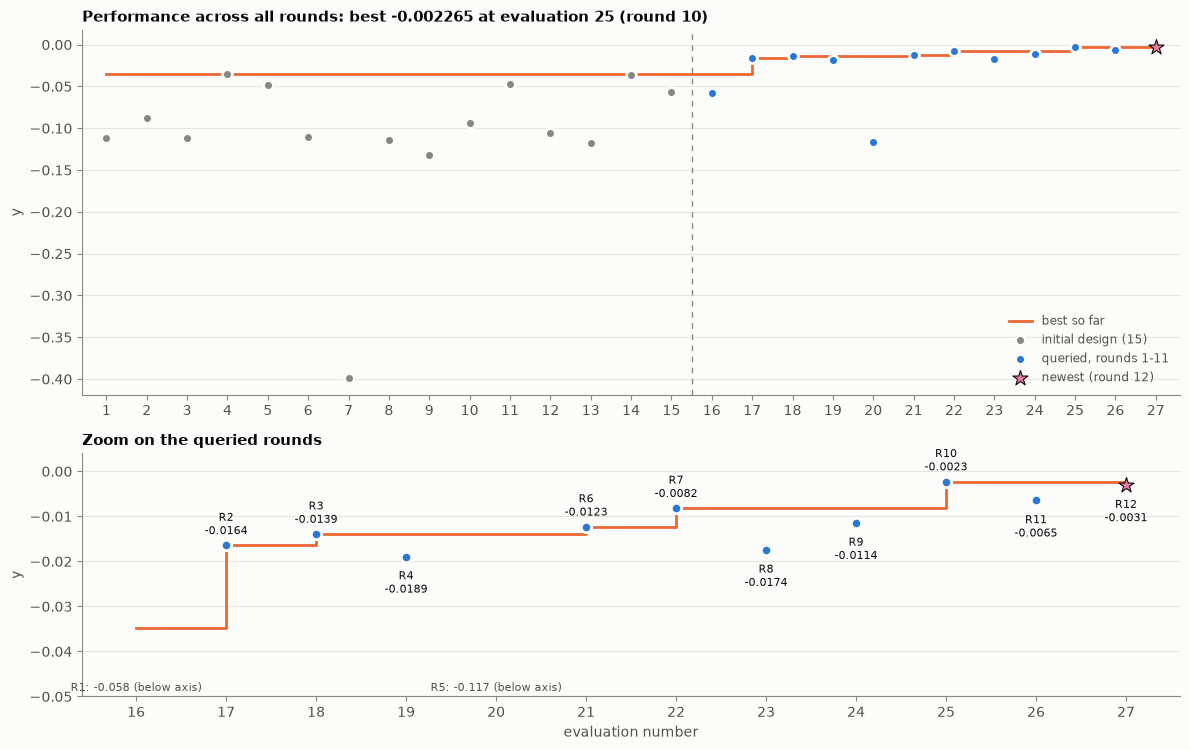

In [ ]:
# Fig 5: performance across all rounds
idx = np.arange(1, n + 1)
bsf = np.maximum.accumulate(np.r_[np.full(N_INITIAL, y[:N_INITIAL].max()), y[N_INITIAL:]])
fig, (ax, az) = plt.subplots(2, 1, figsize=(12, 7.6), height_ratios=[3, 2])
ax.axvline(N_INITIAL + 0.5, color=MUTED, lw=1, ls=(0, (4, 4)))
ax.step(idx, bsf, where="post", color=ORANGE, lw=2, label="best so far", zorder=2)
ax.scatter(idx[:N_INITIAL], y[:N_INITIAL], s=50, color=MUTED, edgecolor=SURFACE, linewidth=2,
           label=f"initial design ({N_INITIAL})", zorder=3)
ax.scatter(idx[N_INITIAL:W12], y[N_INITIAL:W12], s=50, color=BLUE, edgecolor=SURFACE, linewidth=2,
           label=f"queried, rounds 1-{n - N_INITIAL - 1}", zorder=3)
ax.scatter(idx[W12], y[W12], s=130, marker="*", color=MAGENTA, edgecolor=INK, linewidth=0.8, zorder=4,
           label=f"newest (round {n - N_INITIAL})")
ax.set_xticks(idx); ax.set_xlim(0.4, n + 0.6); ax.grid(axis="x", visible=False); ax.set_ylabel("y")
ax.set_title(f"Performance across all rounds: best {BEST:.6f} at evaluation {best + 1} (round {best - N_INITIAL + 1})")
ax.legend(frameon=False, loc="lower right", fontsize=8.5, labelcolor=INK2)
q = np.arange(N_INITIAL, n)
az.step(idx[q], bsf[q], where="post", color=ORANGE, lw=2, zorder=2)
az.scatter(idx[q[:-1]], y[q[:-1]], s=56, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3)
az.scatter(idx[W12], y[W12], s=130, marker="*", color=MAGENTA, edgecolor=INK, linewidth=0.8, zorder=4)
for i in q:
    if y[i] > -0.05:
        az.annotate(f"R{i - N_INITIAL + 1}\n{y[i]:.4f}", (idx[i], y[i]), xytext=(0, 8 if y[i] >= bsf[i] - 1e-12 else -26),
                    textcoords="offset points", ha="center", fontsize=8, color=INK)
    else:
        az.annotate(f"R{i - N_INITIAL + 1}: {y[i]:.3f} (below axis)", (idx[i], -0.05), xytext=(0, 4),
                    textcoords="offset points", ha="center", fontsize=8, color=INK2)
az.set_ylim(-0.05, 0.004); az.set_xticks(idx[q]); az.set_xlim(N_INITIAL + 0.4, n + 0.6)
az.grid(axis="x", visible=False); az.set_xlabel("evaluation number"); az.set_ylabel("y")
az.set_title("Zoom on the queried rounds")
fig.tight_layout()